# PJME Electricity Demand: Data Audit, EDA, and Model Exploration

This notebook is the **exploratory record** of the project: how the dataset was chosen and
audited, what the exploratory analysis showed, and how the LightGBM and XGBoost direct
multi-horizon models were first prototyped.

> **Source of truth.** The reproducible pipeline lives in [`src/`](../src) and is run with
> `python -m src.train`. It reuses the ideas developed here with stricter engineering:
> a regular hourly grid (DST duplicates averaged, missing hours interpolated), purged
> chronological splits, early stopping on a separate slice of the training data, and a single
> evaluation on the untouched test set. **The metrics reported in the README come from that
> pipeline (`reports/metrics.json`), not from the exploratory cells below.**

## 1. Setup

In [1]:
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.metrics import mean_absolute_error, mean_squared_error
import lightgbm as lgb
from xgboost import XGBRegressor

## 2. Dataset selection

The source archive contains several PJM regional hourly load series. They are compared on
length, coverage, and timestamp regularity before one is chosen as the primary series.

In [4]:
# Original Kaggle archive ("Hourly Energy Consumption", PJM regions).
# Place it at data/archive.zip to re-run this dataset-selection section.
data_source = Path("../data/archive.zip")

In [5]:
print(data_source.exists())

True


In [6]:
with zipfile.ZipFile(data_source, "r") as zip_ref:
    file_names = zip_ref.namelist()

print(file_names)

['AEP_hourly.csv', 'COMED_hourly.csv', 'DAYTON_hourly.csv', 'DEOK_hourly.csv', 'DOM_hourly.csv', 'DUQ_hourly.csv', 'EKPC_hourly.csv', 'FE_hourly.csv', 'NI_hourly.csv', 'PJME_hourly.csv', 'PJMW_hourly.csv', 'PJM_Load_hourly.csv', 'est_hourly.paruqet', 'pjm_hourly_est.csv']


In [7]:
hourly_files = [
    name for name in file_names
    if name.endswith("_hourly.csv")
]

print(hourly_files)

['AEP_hourly.csv', 'COMED_hourly.csv', 'DAYTON_hourly.csv', 'DEOK_hourly.csv', 'DOM_hourly.csv', 'DUQ_hourly.csv', 'EKPC_hourly.csv', 'FE_hourly.csv', 'NI_hourly.csv', 'PJME_hourly.csv', 'PJMW_hourly.csv', 'PJM_Load_hourly.csv']


In [8]:
comparison = []

with zipfile.ZipFile(data_source, "r") as zip_ref:
    for file_name in hourly_files:
        with zip_ref.open(file_name) as file:
            df = pd.read_csv(file)

        comparison.append({
            "file": file_name,
            "rows": len(df),
            "columns": len(df.columns),
            "column_names": list(df.columns),
            "start": df.iloc[:, 0].min(),
            "end": df.iloc[:, 0].max()
        })

comparison_df = pd.DataFrame(comparison)

comparison_df

,file,rows,columns,column_names,start,end
0,AEP_hourly.csv,121273,2,"[Datetime, AEP_MW]",2004-10-01 01:00:00,2018-08-03 00:00:00
1,COMED_hourly.csv,66497,2,"[Datetime, COMED_MW]",2011-01-01 01:00:00,2018-08-03 00:00:00
2,DAYTON_hourly.csv,121275,2,"[Datetime, DAYTON_MW]",2004-10-01 01:00:00,2018-08-03 00:00:00
3,DEOK_hourly.csv,57739,2,"[Datetime, DEOK_MW]",2012-01-01 01:00:00,2018-08-03 00:00:00
4,DOM_hourly.csv,116189,2,"[Datetime, DOM_MW]",2005-05-01 01:00:00,2018-08-03 00:00:00
5,DUQ_hourly.csv,119068,2,"[Datetime, DUQ_MW]",2005-01-01 01:00:00,2018-08-03 00:00:00
6,EKPC_hourly.csv,45334,2,"[Datetime, EKPC_MW]",2013-06-01 01:00:00,2018-08-03 00:00:00
7,FE_hourly.csv,62874,2,"[Datetime, FE_MW]",2011-06-01 01:00:00,2018-08-03 00:00:00
8,NI_hourly.csv,58450,2,"[Datetime, NI_MW]",2004-05-01 01:00:00,2011-01-01 00:00:00
9,PJME_hourly.csv,145366,2,"[Datetime, PJME_MW]",2002-01-01 01:00:00,2018-08-03 00:00:00


In [9]:
timestamp_checks = []

with zipfile.ZipFile(data_source, "r") as zip_ref:
    for file_name in hourly_files:
        with zip_ref.open(file_name) as file:
            df = pd.read_csv(file)

        timestamp_column = df.columns[0]

        df[timestamp_column] = pd.to_datetime(
            df[timestamp_column],
            errors="coerce"
        )

        df = df.sort_values(timestamp_column)

        time_diff = df[timestamp_column].diff()

        timestamp_checks.append({
            "file": file_name,
            "invalid_timestamps": df[timestamp_column].isna().sum(),
            "duplicate_timestamps": df[timestamp_column].duplicated().sum(),
            "min_gap": time_diff.min(),
            "max_gap": time_diff.max(),
            "median_gap": time_diff.median()
        })

timestamp_checks_df = pd.DataFrame(timestamp_checks)

timestamp_checks_df

,file,invalid_timestamps,duplicate_timestamps,min_gap,max_gap,median_gap
0,AEP_hourly.csv,0,4,0 days 00:00:00,0 days 02:00:00,0 days 01:00:00
1,COMED_hourly.csv,0,4,0 days 00:00:00,0 days 02:00:00,0 days 01:00:00
2,DAYTON_hourly.csv,0,4,0 days 00:00:00,0 days 02:00:00,0 days 01:00:00
3,DEOK_hourly.csv,0,4,0 days 00:00:00,0 days 02:00:00,0 days 01:00:00
4,DOM_hourly.csv,0,4,0 days 00:00:00,0 days 02:00:00,0 days 01:00:00
5,DUQ_hourly.csv,0,4,0 days 00:00:00,0 days 02:00:00,0 days 01:00:00
6,EKPC_hourly.csv,0,4,0 days 00:00:00,0 days 02:00:00,0 days 01:00:00
7,FE_hourly.csv,0,4,0 days 00:00:00,0 days 02:00:00,0 days 01:00:00
8,NI_hourly.csv,0,0,0 days 01:00:00,0 days 02:00:00,0 days 01:00:00
9,PJME_hourly.csv,0,4,0 days 00:00:00,0 days 02:00:00,0 days 01:00:00


In [10]:
candidate_files = ["PJME_hourly.csv", "PJMW_hourly.csv"]

duplicate_details = []

with zipfile.ZipFile(data_source, "r") as zip_ref:
    for file_name in candidate_files:
        with zip_ref.open(file_name) as file:
            df = pd.read_csv(file)

        timestamp_column = df.columns[0]

        df[timestamp_column] = pd.to_datetime(
            df[timestamp_column],
            errors="coerce"
        )

        duplicates = df[df[timestamp_column].duplicated(keep=False)].sort_values(
            timestamp_column
        )

        duplicate_details.append({
            "file": file_name,
            "duplicate_rows": len(duplicates),
            "duplicate_timestamps": duplicates[timestamp_column].nunique(),
            "timestamps": duplicates[timestamp_column].tolist()
        })

duplicate_details_df = pd.DataFrame(duplicate_details)

duplicate_details_df

,file,duplicate_rows,duplicate_timestamps,timestamps
0,PJME_hourly.csv,8,4,"[2014-11-02 02:00:00, 2014-11-02 02:00:00, 201..."
1,PJMW_hourly.csv,8,4,"[2014-11-02 02:00:00, 2014-11-02 02:00:00, 201..."


In [11]:
duplicate_values = {}

with zipfile.ZipFile(data_source, "r") as zip_ref:
    for file_name in candidate_files:
        with zip_ref.open(file_name) as file:
            df = pd.read_csv(file)

        timestamp_column = df.columns[0]

        df[timestamp_column] = pd.to_datetime(
            df[timestamp_column],
            errors="coerce"
        )

        duplicates = df[
            df[timestamp_column].duplicated(keep=False)
        ].sort_values(timestamp_column)

        duplicate_values[file_name] = duplicates

duplicate_values["PJMW_hourly.csv"]

,Datetime,PJMW_MW
104424,2014-11-02 02:00:00,4613.0
104425,2014-11-02 02:00:00,4571.0
113208,2015-11-01 02:00:00,3927.0
113209,2015-11-01 02:00:00,3832.0
121848,2016-11-06 02:00:00,4114.0
121849,2016-11-06 02:00:00,4089.0
130656,2017-11-05 02:00:00,4042.0
130657,2017-11-05 02:00:00,3984.0


In [12]:
with zipfile.ZipFile(data_source, "r") as zip_ref:
    with zip_ref.open("PJME_hourly.csv") as file:
        df = pd.read_csv(file)

timestamp_column = df.columns[0]

df[timestamp_column] = pd.to_datetime(
    df[timestamp_column],
    errors="coerce"
)

start_time = pd.Timestamp("2014-11-02 00:00:00")
end_time = pd.Timestamp("2014-11-02 05:00:00")

df[
    (df[timestamp_column] >= start_time)
    & (df[timestamp_column] <= end_time)
]

,Datetime,PJME_MW
106583,2014-11-02 01:00:00,23538.0
106584,2014-11-02 02:00:00,22935.0
106585,2014-11-02 02:00:00,23755.0
106586,2014-11-02 03:00:00,22789.0
106587,2014-11-02 04:00:00,22555.0
106588,2014-11-02 05:00:00,23247.0
106631,2014-11-02 00:00:00,25838.0


In [13]:
value_checks = []

with zipfile.ZipFile(data_source, "r") as zip_ref:
    for file_name in candidate_files:
        with zip_ref.open(file_name) as file:
            df = pd.read_csv(file)

        target_column = df.columns[1]

        value_checks.append({
            "file": file_name,
            "missing_target": df[target_column].isna().sum(),
            "zero_or_negative": (df[target_column] <= 0).sum(),
            "min_value": df[target_column].min(),
            "max_value": df[target_column].max()
        })

value_checks_df = pd.DataFrame(value_checks)

value_checks_df

,file,missing_target,zero_or_negative,min_value,max_value
0,PJME_hourly.csv,0,0,14544.0,62009.0
1,PJMW_hourly.csv,0,0,487.0,9594.0


In [14]:
with zipfile.ZipFile(data_source, "r") as zip_ref:
    with zip_ref.open("PJME_hourly.csv") as file:
        pjme_df = pd.read_csv(file)

timestamp_column = pjme_df.columns[0]

pjme_df[timestamp_column] = pd.to_datetime(
    pjme_df[timestamp_column],
    errors="coerce"
)

pjme_df = pjme_df.sort_values(timestamp_column)

time_diff = pjme_df[timestamp_column].diff()

pjme_df.loc[
    time_diff > pd.Timedelta(hours=1),
    [timestamp_column]
].assign(gap=time_diff[time_diff > pd.Timedelta(hours=1)])

,Datetime,gap
6433,2002-04-07 04:00:00,0 days 02:00:00
1561,2002-10-27 03:00:00,0 days 02:00:00
15215,2003-04-06 04:00:00,0 days 02:00:00
10343,2003-10-26 03:00:00,0 days 02:00:00
24021,2004-04-04 04:00:00,0 days 02:00:00
18981,2004-10-31 03:00:00,0 days 02:00:00
32827,2005-04-03 04:00:00,0 days 02:00:00
27787,2005-10-30 03:00:00,0 days 02:00:00
41609,2006-04-02 04:00:00,0 days 02:00:00
36569,2006-10-29 03:00:00,0 days 02:00:00


## 3. Data audit of the selected series (PJME)

Schema, ordering, duplicate timestamps, time intervals, missing values, and value validity.

In [15]:
data_path = Path("../data/PJME_hourly.csv")

print("Dataset path:", data_path)
print("File exists:", data_path.exists())

Dataset path: ..\data\PJME_hourly.csv
File exists: True


In [16]:
df = pd.read_csv("../data/PJME_hourly.csv")
df.head()

,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0


In [17]:
expected_columns = ["Datetime", "PJME_MW"]

actual_columns = df.columns.tolist()

print("Schema valid:", actual_columns == expected_columns)
print("\nData types:")
print(df.dtypes)

Schema valid: True

Data types:
Datetime        str
PJME_MW     float64
dtype: object


In [18]:
df["Datetime"] = pd.to_datetime(df["Datetime"])

df = df.sort_values("Datetime").reset_index(drop=True)

print(df["Datetime"].min())
print(df["Datetime"].max())

2002-01-01 01:00:00
2018-08-03 00:00:00


In [19]:
before_count = len(df)
duplicate_count = df["Datetime"].duplicated().sum()

print(f"Row count before: {before_count}")
print(f"Duplicate timestamps found: {duplicate_count}")

df = df.drop_duplicates(subset="Datetime", keep="first").reset_index(drop=True)

after_count = len(df)
print(f"Row count after: {after_count}")
print(f"Rows removed: {before_count - after_count}")

assert df["Datetime"].duplicated().sum() == 0
print("Confirmed: no duplicate timestamps remaining.")

Row count before: 145366
Duplicate timestamps found: 4
Row count after: 145362
Rows removed: 4
Confirmed: no duplicate timestamps remaining.


In [20]:
time_diff = df["Datetime"].diff().dropna()

print("Median interval:", time_diff.median())
print("Minimum interval:", time_diff.min())
print("Maximum interval:", time_diff.max())

print("\nIntervals other than 1 hour:")
print((time_diff != pd.Timedelta(hours=1)).sum())

Median interval: 0 days 01:00:00
Minimum interval: 0 days 01:00:00
Maximum interval: 0 days 02:00:00

Intervals other than 1 hour:
30


In [21]:
missing_values = df.isna().sum()

print(missing_values)

Datetime    0
PJME_MW     0
dtype: int64


In [22]:
duplicate_rows = df.duplicated().sum()

print("Exact duplicate rows:", duplicate_rows)

Exact duplicate rows: 0


In [23]:
print("Target dtype:", df["PJME_MW"].dtype)
print("Infinite values:", np.isinf(df["PJME_MW"]).sum())

Target dtype: float64
Infinite values: 0


## 4. Exploratory data analysis

Long-term behaviour, daily/weekly/monthly profiles, peak-demand observations, and the
autocorrelation structure that motivates the lag features.

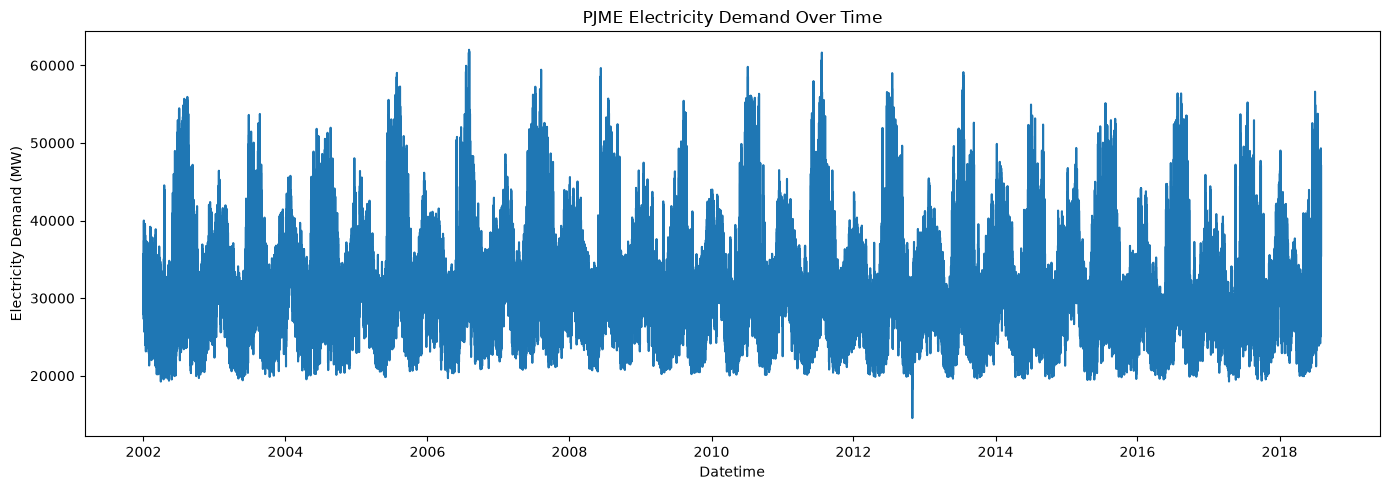

In [24]:
plt.figure(figsize=(14, 5))

plt.plot(df["Datetime"], df["PJME_MW"])

plt.title("PJME Electricity Demand Over Time")
plt.xlabel("Datetime")
plt.ylabel("Electricity Demand (MW)")

plt.tight_layout()
plt.show()

In [25]:
daily = df.set_index("Datetime")["PJME_MW"].resample("D").mean()
weekly = df.set_index("Datetime")["PJME_MW"].resample("W").mean()

print("Daily observations:", len(daily))
print("Weekly observations:", len(weekly))

Daily observations: 6059
Weekly observations: 866


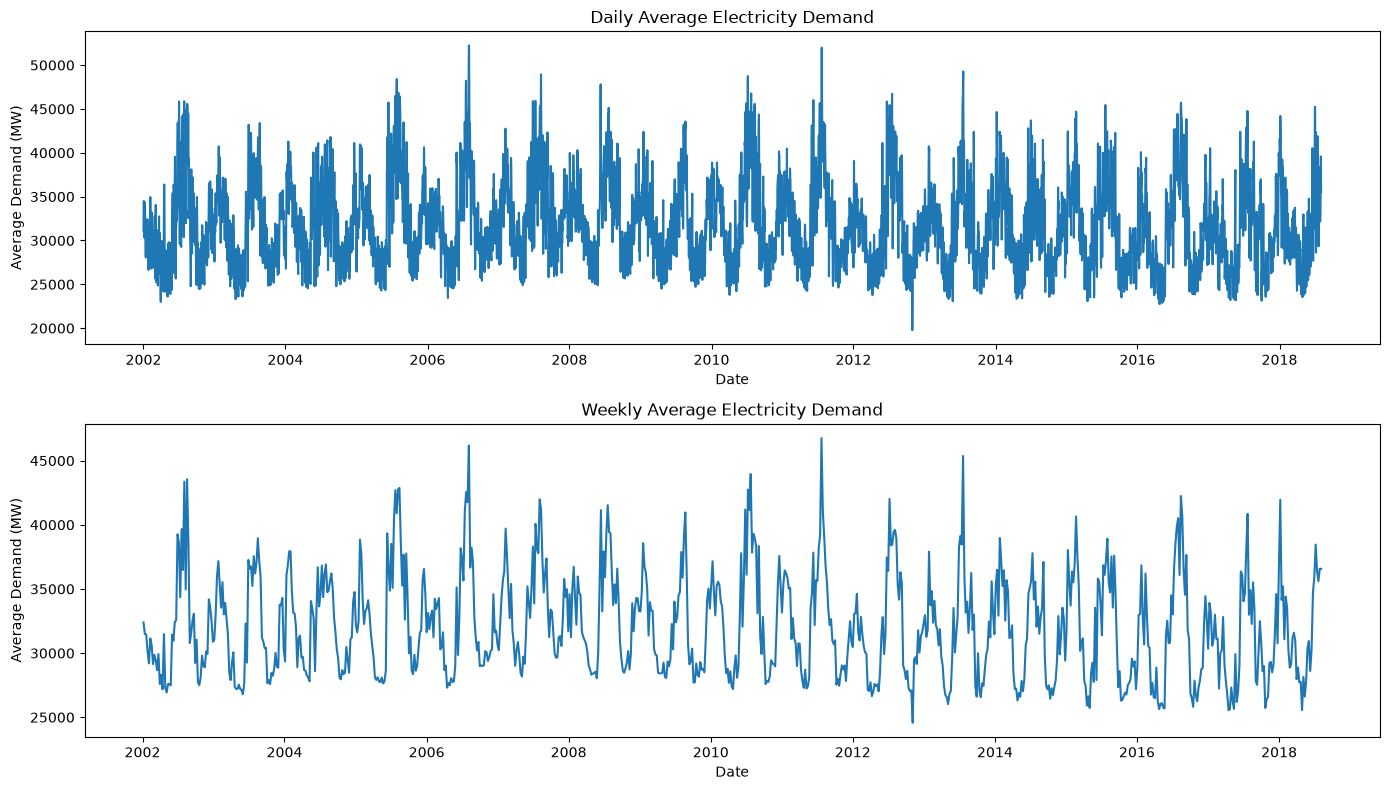

In [26]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)

axes[0].plot(daily.index, daily.values)
axes[0].set_title("Daily Average Electricity Demand")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Average Demand (MW)")

axes[1].plot(weekly.index, weekly.values)
axes[1].set_title("Weekly Average Electricity Demand")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Average Demand (MW)")

plt.tight_layout()
plt.show()

In [27]:
hourly_profile = (
    df.groupby(df["Datetime"].dt.hour)["PJME_MW"]
    .mean()
)

hourly_profile

Datetime
0     29523.611194
1     27535.589964
2     26347.183262
3     25679.097666
4     25414.924728
5     25749.431000
6     27162.853912
7     29611.046880
8     31490.827831
9     32628.888247
10    33497.403433
11    34197.643117
12    34588.618356
13    34759.571146
14    34916.601684
15    34940.669693
16    35065.392209
17    35596.051502
18    36421.931496
19    36426.629911
20    36106.840211
21    35741.057280
22    34453.149884
23    32047.501486
Name: PJME_MW, dtype: float64

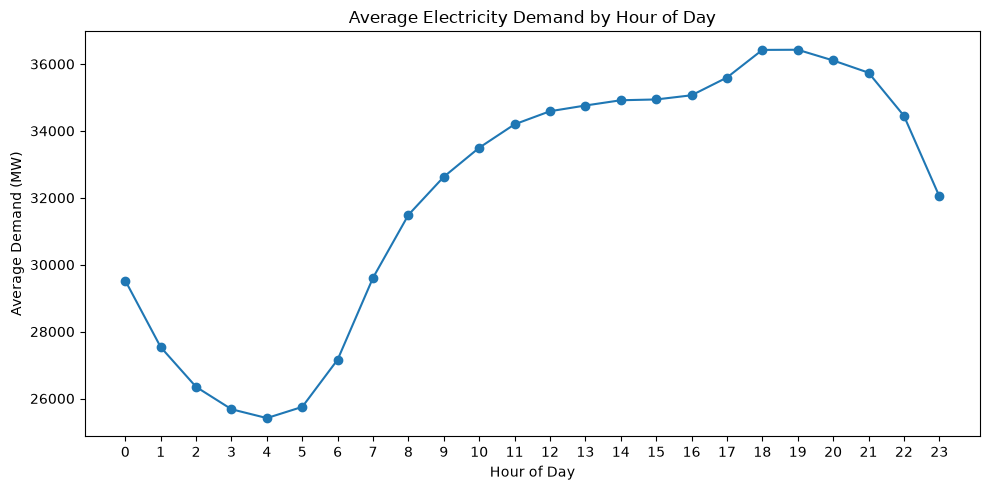

In [28]:
plt.figure(figsize=(10, 5))

plt.plot(
    hourly_profile.index,
    hourly_profile.values,
    marker="o"
)

plt.title("Average Electricity Demand by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Average Demand (MW)")
plt.xticks(range(24))

plt.tight_layout()
plt.show()

In [29]:
weekly_profile = (
    df.groupby(df["Datetime"].dt.dayofweek)["PJME_MW"]
    .mean()
)

weekly_profile

Datetime
0    32672.028420
1    33272.265746
2    33261.497498
3    33085.857727
4    32688.097688
5    30162.880588
6    29413.374126
Name: PJME_MW, dtype: float64

In [30]:
monthly_profile = (
    df.groupby(df["Datetime"].dt.month)["PJME_MW"]
    .mean()
)

monthly_profile

Datetime
1     34343.246462
2     33434.972049
3     30514.903609
4     27863.339354
5     28695.362113
6     33811.799183
7     37881.972881
8     36595.959675
9     31484.054688
10    28119.228675
11    29331.413533
12    32676.247669
Name: PJME_MW, dtype: float64

In [31]:
peak_threshold = df["PJME_MW"].quantile(0.99)

peak_count = (df["PJME_MW"] >= peak_threshold).sum()

print("99th percentile:", peak_threshold)
print("Peak observations:", peak_count)

99th percentile: 51156.55999999994
Peak observations: 1454


In [32]:
peak_df = df[df["PJME_MW"] >= peak_threshold].copy()

peak_df["hour"] = peak_df["Datetime"].dt.hour
peak_df["day_of_week"] = peak_df["Datetime"].dt.dayofweek
peak_df["month"] = peak_df["Datetime"].dt.month

peak_df[["Datetime", "PJME_MW", "hour", "day_of_week", "month"]].head(10)

,Datetime,PJME_MW,hour,day_of_week,month
4215,2002-06-25 17:00:00,51414.0,17,1,6
4235,2002-06-26 13:00:00,51677.0,13,2,6
4236,2002-06-26 14:00:00,52637.0,14,2,6
4237,2002-06-26 15:00:00,52938.0,15,2,6
4238,2002-06-26 16:00:00,52894.0,16,2,6
4239,2002-06-26 17:00:00,52148.0,17,2,6
4260,2002-06-27 14:00:00,51362.0,14,3,6
4261,2002-06-27 15:00:00,52115.0,15,3,6
4262,2002-06-27 16:00:00,52410.0,16,3,6
4263,2002-06-27 17:00:00,52137.0,17,3,6


In [33]:
peak_by_month = (
    peak_df.groupby("month")
    .size()
)
peak_by_month

month
5      7
6    193
7    750
8    448
9     56
dtype: int64

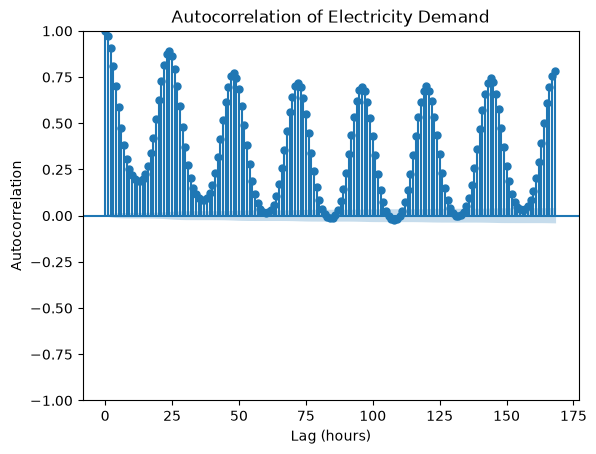

In [34]:
plot_acf(df["PJME_MW"].dropna(), lags=168, alpha=0.05)

plt.title("Autocorrelation of Electricity Demand")
plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.show()

## 5. Feature engineering

Lag features chosen from the ACF (1, 24, 48, 168 h), calendar features, a cyclical hour
encoding, and rolling means over windows that end one hour before the forecast origin.

In [35]:
df["lag_1"] = df["PJME_MW"].shift(1)
df["lag_24"] = df["PJME_MW"].shift(24)
df["lag_48"] = df["PJME_MW"].shift(48)
df["lag_168"] = df["PJME_MW"].shift(168)

df.head(30)

,Datetime,PJME_MW,lag_1,lag_24,lag_48,lag_168
0,2002-01-01 01:00:00,30393.0,NaN,NaN,NaN,NaN
1,2002-01-01 02:00:00,29265.0,30393.0,NaN,NaN,NaN
2,2002-01-01 03:00:00,28357.0,29265.0,NaN,NaN,NaN
3,2002-01-01 04:00:00,27899.0,28357.0,NaN,NaN,NaN
4,2002-01-01 05:00:00,28057.0,27899.0,NaN,NaN,NaN
5,2002-01-01 06:00:00,28654.0,28057.0,NaN,NaN,NaN
6,2002-01-01 07:00:00,29308.0,28654.0,NaN,NaN,NaN
7,2002-01-01 08:00:00,29595.0,29308.0,NaN,NaN,NaN
8,2002-01-01 09:00:00,29943.0,29595.0,NaN,NaN,NaN
9,2002-01-01 10:00:00,30692.0,29943.0,NaN,NaN,NaN


In [36]:
df["Datetime"] = pd.to_datetime(df["Datetime"])
print(df["Datetime"].dtype)

datetime64[us]


In [37]:
df["hour"] = df["Datetime"].dt.hour
df["day_of_week"] = df["Datetime"].dt.dayofweek
df["month"] = df["Datetime"].dt.month
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

df.head()

,Datetime,PJME_MW,lag_1,lag_24,lag_48,lag_168,hour,day_of_week,month,is_weekend
0,2002-01-01 01:00:00,30393.0,NaN,NaN,NaN,NaN,1,1,1,0
1,2002-01-01 02:00:00,29265.0,30393.0,NaN,NaN,NaN,2,1,1,0
2,2002-01-01 03:00:00,28357.0,29265.0,NaN,NaN,NaN,3,1,1,0
3,2002-01-01 04:00:00,27899.0,28357.0,NaN,NaN,NaN,4,1,1,0
4,2002-01-01 05:00:00,28057.0,27899.0,NaN,NaN,NaN,5,1,1,0


In [38]:
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

df[["hour", "hour_sin", "hour_cos"]].head()

,hour,hour_sin,hour_cos
0,1,0.258819,0.965926
1,2,0.500000,0.866025
2,3,0.707107,0.707107
3,4,0.866025,0.500000
4,5,0.965926,0.258819


In [39]:
df["rolling_mean_24"] = df["PJME_MW"].shift(1).rolling(24).mean()

In [40]:
df["rolling_mean_168"] = df["PJME_MW"].shift(1).rolling(168).mean()

In [41]:
df.isna().sum()

Datetime              0
PJME_MW               0
lag_1                 1
lag_24               24
lag_48               48
lag_168             168
hour                  0
day_of_week           0
month                 0
is_weekend            0
hour_sin              0
hour_cos              0
rolling_mean_24      24
rolling_mean_168    168
dtype: int64

In [42]:
df = df.dropna()

In [43]:
df.shape

(145194, 14)

In [44]:
df["Datetime"].min(), df["Datetime"].max()

(Timestamp('2002-01-08 01:00:00'), Timestamp('2018-08-03 00:00:00'))

## 6. Chronological split and baselines

70 / 15 / 15 split by time, no shuffling. Naive and seasonal-naive forecasts set the bar that
any model must beat, both for one-step and for 24-step forecasts.

In [45]:
train_size = int(len(df) * 0.70)
val_size = int(len(df) * 0.15)

train = df.iloc[:train_size].copy()
val = df.iloc[train_size:train_size + val_size].copy()
test = df.iloc[train_size + val_size:].copy()

In [46]:
print("Train:", train.shape)
print("Validation:", val.shape)
print("Test:", test.shape)

Train: (101635, 14)
Validation: (21779, 14)
Test: (21780, 14)


In [47]:
print("Train:", train["Datetime"].min(), "→", train["Datetime"].max())
print("Validation:", val["Datetime"].min(), "→", val["Datetime"].max())
print("Test:", test["Datetime"].min(), "→", test["Datetime"].max())

Train: 2002-01-08 01:00:00 → 2013-08-13 19:00:00
Validation: 2013-08-13 20:00:00 → 2016-02-07 09:00:00
Test: 2016-02-07 10:00:00 → 2018-08-03 00:00:00


In [48]:
y_val = val["PJME_MW"]

y_pred_naive = val["PJME_MW"].shift(1)

y_pred_naive = y_pred_naive.dropna()
y_val_naive = y_val.loc[y_pred_naive.index]

In [49]:
y_pred_naive.head()

101804    41163.0
101805    41033.0
101806    39105.0
101807    35872.0
101808    32551.0
Name: PJME_MW, dtype: float64

In [50]:
y_pred_seasonal_24 = val["PJME_MW"].shift(24)

y_pred_seasonal_24 = y_pred_seasonal_24.dropna()
y_val_seasonal_24 = val["PJME_MW"].loc[y_pred_seasonal_24.index]

y_pred_seasonal_24.head()

101827    41163.0
101828    41033.0
101829    39105.0
101830    35872.0
101831    32551.0
Name: PJME_MW, dtype: float64

In [51]:

mae_seasonal_24 = mean_absolute_error(
    y_val_seasonal_24,
    y_pred_seasonal_24
)

rmse_seasonal_24 = np.sqrt(
    mean_squared_error(
        y_val_seasonal_24,
        y_pred_seasonal_24
    )
)

print("Seasonal Naive 24h MAE:", mae_seasonal_24)
print("Seasonal Naive 24h RMSE:", rmse_seasonal_24)

Seasonal Naive 24h MAE: 2241.2901861641003
Seasonal Naive 24h RMSE: 3062.6168519567086


In [52]:
mae_naive = mean_absolute_error(y_val_naive, y_pred_naive)
rmse_naive = np.sqrt(mean_squared_error(y_val_naive, y_pred_naive))

print("Naive MAE:", mae_naive)
print("Naive RMSE:", rmse_naive)

Naive MAE: 1064.343741390394
Naive RMSE: 1379.522821581111


In [53]:
y_pred_seasonal_168 = val["PJME_MW"].shift(168)

y_pred_seasonal_168 = y_pred_seasonal_168.dropna()
y_val_seasonal_168 = val["PJME_MW"].loc[y_pred_seasonal_168.index]

y_pred_seasonal_168.head()

101971    41163.0
101972    41033.0
101973    39105.0
101974    35872.0
101975    32551.0
Name: PJME_MW, dtype: float64

In [54]:
mae_seasonal_168 = mean_absolute_error(
    y_val_seasonal_168,
    y_pred_seasonal_168
)

rmse_seasonal_168 = np.sqrt(
    mean_squared_error(
        y_val_seasonal_168,
        y_pred_seasonal_168
    )
)

print("Seasonal Naive 168h MAE:", mae_seasonal_168)
print("Seasonal Naive 168h RMSE:", rmse_seasonal_168)

Seasonal Naive 168h MAE: 3163.8358243487114
Seasonal Naive 168h RMSE: 4283.349302619762


In [55]:
y_true_24 = []
y_pred_24 = []

series = pd.concat([train["PJME_MW"], val["PJME_MW"]])

start = len(train)

for i in range(start, len(series) - 24 + 1, 24):
    last_value = series.iloc[i - 1]
    actual = series.iloc[i:i + 24].values
    prediction = np.repeat(last_value, 24)

    y_true_24.extend(actual)
    y_pred_24.extend(prediction)

y_true_24 = np.array(y_true_24)
y_pred_24 = np.array(y_pred_24)

print("Number of forecasts:", len(y_true_24))

Number of forecasts: 21768


In [56]:
mae_naive_24 = mean_absolute_error(y_true_24, y_pred_24)
rmse_naive_24 = np.sqrt(mean_squared_error(y_true_24, y_pred_24))

print("Naive 24h MAE:", mae_naive_24)
print("Naive 24h RMSE:", rmse_naive_24)

Naive 24h MAE: 4433.547500918779
Naive 24h RMSE: 5652.1671384919255


In [57]:
y_true_seasonal_24 = []
y_pred_seasonal_24 = []

for i in range(start, len(series) - 24 + 1, 24):
    actual = series.iloc[i:i + 24].values
    prediction = series.iloc[i - 24:i].values

    y_true_seasonal_24.extend(actual)
    y_pred_seasonal_24.extend(prediction)

y_true_seasonal_24 = np.array(y_true_seasonal_24)
y_pred_seasonal_24 = np.array(y_pred_seasonal_24)

print("Number of forecasts:", len(y_true_seasonal_24))

Number of forecasts: 21768


In [58]:
mae_seasonal_24 = mean_absolute_error(
    y_true_seasonal_24,
    y_pred_seasonal_24
)

rmse_seasonal_24 = np.sqrt(
    mean_squared_error(
        y_true_seasonal_24,
        y_pred_seasonal_24
    )
)

print("Seasonal Naive 24h MAE:", mae_seasonal_24)
print("Seasonal Naive 24h RMSE:", rmse_seasonal_24)

Seasonal Naive 24h MAE: 2244.366087835355
Seasonal Naive 24h RMSE: 3066.3197772928143


In [59]:
y_true_seasonal_168_24 = []
y_pred_seasonal_168_24 = []

for i in range(start, len(series) - 24 + 1, 24):
    actual = series.iloc[i:i + 24].values
    prediction = series.iloc[i - 168:i - 144].values

    y_true_seasonal_168_24.extend(actual)
    y_pred_seasonal_168_24.extend(prediction)

y_true_seasonal_168_24 = np.array(y_true_seasonal_168_24)
y_pred_seasonal_168_24 = np.array(y_pred_seasonal_168_24)

print("Number of forecasts:", len(y_true_seasonal_168_24))

Number of forecasts: 21768


In [60]:
mae_seasonal_168_24 = mean_absolute_error(
    y_true_seasonal_168_24,
    y_pred_seasonal_168_24
)

rmse_seasonal_168_24 = np.sqrt(
    mean_squared_error(
        y_true_seasonal_168_24,
        y_pred_seasonal_168_24
    )
)

print("Seasonal Naive 168h MAE:", mae_seasonal_168_24)
print("Seasonal Naive 168h RMSE:", rmse_seasonal_168_24)

Seasonal Naive 168h MAE: 3182.3795479603086
Seasonal Naive 168h RMSE: 4300.695927291584


## 7. Adding 30-day context

A 720-hour lag and rolling mean are added; the split is recomputed on the final feature set
and the 24 direct-horizon targets (`target_1` … `target_24`) are built inside each partition.

In [64]:
df["lag_720"] = df["PJME_MW"].shift(720)

df["rolling_mean_720"] = (
    df["PJME_MW"]
    .shift(1)
    .rolling(720)
    .mean()
)

In [65]:
df[["lag_720", "rolling_mean_720"]].isna().sum()

lag_720             720
rolling_mean_720    720
dtype: int64

In [66]:
feature_cols = [
    "PJME_MW",
    "lag_1",
    "lag_24",
    "lag_48",
    "lag_168",
    "lag_720",
    "hour",
    "day_of_week",
    "month",
    "is_weekend",
    "hour_sin",
    "hour_cos",
    "rolling_mean_24",
    "rolling_mean_168",
    "rolling_mean_720"
]

df[feature_cols].isna().sum() 

PJME_MW               0
lag_1                 0
lag_24                0
lag_48                0
lag_168               0
lag_720             720
hour                  0
day_of_week           0
month                 0
is_weekend            0
hour_sin              0
hour_cos              0
rolling_mean_24       0
rolling_mean_168      0
rolling_mean_720    720
dtype: int64

In [67]:
df = df.dropna()

In [68]:
df.shape

(144474, 16)

In [69]:
df["Datetime"].min(), df["Datetime"].max()

(Timestamp('2002-02-07 01:00:00'), Timestamp('2018-08-03 00:00:00'))

In [72]:
train_size = int(len(df) * 0.70)
val_size = int(len(df) * 0.15)

train = df.iloc[:train_size].copy()
val = df.iloc[train_size:train_size + val_size].copy()
test = df.iloc[train_size + val_size:].copy()

print("Train:", train.shape)
print("Validation:", val.shape)
print("Test:", test.shape)

Train: (101131, 16)
Validation: (21671, 16)
Test: (21672, 16)


In [73]:
train_lgb = train.copy()

for h in range(1, 25):
    train_lgb[f"target_{h}"] = train_lgb["PJME_MW"].shift(-h)

train_lgb = train_lgb.dropna()

print(train_lgb.shape)

(101107, 40)


In [74]:
target_cols = [f"target_{h}" for h in range(1, 25)]

X_train = train_lgb[feature_cols]
y_train = train_lgb[target_cols]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

X_train: (101107, 15)
y_train: (101107, 24)


In [75]:
val_lgb = val.copy()

for h in range(1, 25):
    val_lgb[f"target_{h}"] = val_lgb["PJME_MW"].shift(-h)

val_lgb = val_lgb.dropna()

X_val = val_lgb[feature_cols]
y_val = val_lgb[target_cols]

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

X_val: (21647, 15)
y_val: (21647, 24)


## 8. LightGBM: one model per horizon

In [76]:
print(lgb.__version__)

4.7.0


In [77]:
lgb_params = {
    "objective": "regression",
    "n_estimators": 2000,
    "learning_rate": 0.03,
    "num_leaves": 63,
    "max_depth": -1,
    "min_child_samples": 30,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.1,
    "reg_lambda": 0.5,
    "random_state": 42,
    "n_jobs": -1
}

In [78]:
model_h1 = lgb.LGBMRegressor(**lgb_params)

model_h1.fit(
    X_train,
    y_train["target_1"],
    eval_set=[(X_val, y_val["target_1"])],
    eval_metric=["mae", "rmse"],
    callbacks=[
        lgb.early_stopping(100),
        lgb.log_evaluation(100)
    ]
)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003959 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2380
[LightGBM] [Info] Number of data points in the train set: 101107, number of used features: 15
[LightGBM] [Info] Start training from score 32424.735755
Training until validation scores don't improve for 100 rounds


c:\Users\Admin\Downloads\electricity-demand-forecasting\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[100]	valid_0's l1: 512.377	valid_0's rmse: 649.822	valid_0's l2: 422269
[200]	valid_0's l1: 329.075	valid_0's rmse: 443.792	valid_0's l2: 196952
[300]	valid_0's l1: 289.868	valid_0's rmse: 395.622	valid_0's l2: 156516
[400]	valid_0's l1: 272.663	valid_0's rmse: 374.123	valid_0's l2: 139968
[500]	valid_0's l1: 261.203	valid_0's rmse: 359.866	valid_0's l2: 129504
[600]	valid_0's l1: 253.564	valid_0's rmse: 350.407	valid_0's l2: 122785
[700]	valid_0's l1: 248.497	valid_0's rmse: 344.238	valid_0's l2: 118500
[800]	valid_0's l1: 244.26	valid_0's rmse: 339.106	valid_0's l2: 114993
[900]	valid_0's l1: 240.541	valid_0's rmse: 334.423	valid_0's l2: 111839
[1000]	valid_0's l1: 237.806	valid_0's rmse: 331.068	valid_0's l2: 109606
[1100]	valid_0's l1: 235.357	valid_0's rmse: 328.202	valid_0's l2: 107717
[1200]	valid_0's l1: 233.346	valid_0's rmse: 325.79	valid_0's l2: 106139
[1300]	valid_0's l1: 231.628	valid_0's rmse: 323.805	valid_0's l2: 104850
[1400]	valid_0's l1: 229.961	valid_0's rmse: 321.

,num_leaves,63
,learning_rate,0.03
,n_estimators,2000
,objective,'regression'
,min_child_samples,30
,subsample,0.8
,colsample_bytree,0.8
,reg_alpha,0.1
,reg_lambda,0.5
,random_state,42
,n_jobs,-1


In [79]:
y_pred_h1 = model_h1.predict(X_val)

print("Predictions shape:", y_pred_h1.shape)

Predictions shape: (21647,)


In [80]:
mae_h1 = mean_absolute_error(y_val["target_1"], y_pred_h1)
rmse_h1 = np.sqrt(mean_squared_error(y_val["target_1"], y_pred_h1))

print(f"Horizon 1 MAE:  {mae_h1:.2f} MW")
print(f"Horizon 1 RMSE: {rmse_h1:.2f} MW")

Horizon 1 MAE:  224.01 MW
Horizon 1 RMSE: 314.88 MW


In [81]:
y_true_h1 = y_val["target_1"]

naive_pred_h1 = val_lgb["PJME_MW"].values

naive_mae_h1 = mean_absolute_error(y_true_h1, naive_pred_h1)
naive_rmse_h1 = np.sqrt(mean_squared_error(y_true_h1, naive_pred_h1))

print(f"Naive 1h MAE:  {naive_mae_h1:.2f} MW")
print(f"Naive 1h RMSE: {naive_rmse_h1:.2f} MW")

Naive 1h MAE:  1062.15 MW
Naive 1h RMSE: 1377.73 MW


In [83]:
# Seasonal naive for horizon 1: the value 24 hours before t+1, i.e. shift(23).
seasonal_naive_pred_h1 = df["PJME_MW"].shift(23).loc[y_val.index].values

seasonal_naive_mae_h1 = mean_absolute_error(
    y_true_h1,
    seasonal_naive_pred_h1
)

seasonal_naive_rmse_h1 = np.sqrt(
    mean_squared_error(
        y_true_h1,
        seasonal_naive_pred_h1
    )
)

print(f"Seasonal Naive 1h MAE: {seasonal_naive_mae_h1:.2f} MW")
print(f"Seasonal Naive 1h RMSE: {seasonal_naive_rmse_h1:.2f} MW")

Seasonal Naive 1h MAE: 2237.48 MW
Seasonal Naive 1h RMSE: 3057.76 MW


In [84]:
target_cols = [f"target_{h}" for h in range(1, 25)]

print("Number of targets:", len(target_cols))
print("Target columns:", target_cols)

print("\nTrain shape:", X_train.shape)
print("Validation shape:", X_val.shape)

print("\nTargets in X_train:")
print([col for col in target_cols if col in X_train.columns])

print("\nTargets in X_val:")
print([col for col in target_cols if col in X_val.columns])

Number of targets: 24
Target columns: ['target_1', 'target_2', 'target_3', 'target_4', 'target_5', 'target_6', 'target_7', 'target_8', 'target_9', 'target_10', 'target_11', 'target_12', 'target_13', 'target_14', 'target_15', 'target_16', 'target_17', 'target_18', 'target_19', 'target_20', 'target_21', 'target_22', 'target_23', 'target_24']

Train shape: (101107, 15)
Validation shape: (21647, 15)

Targets in X_train:
[]

Targets in X_val:
[]


In [85]:
Y_train_24 = train_lgb[target_cols].copy()
Y_val_24 = val_lgb[target_cols].copy()

print("Y_train_24 shape:", Y_train_24.shape)
print("Y_val_24 shape:", Y_val_24.shape)

print("\nMissing values in Y_train_24:")
print(Y_train_24.isna().sum().sum())

print("\nMissing values in Y_val_24:")
print(Y_val_24.isna().sum().sum())

Y_train_24 shape: (101107, 24)
Y_val_24 shape: (21647, 24)

Missing values in Y_train_24:
0

Missing values in Y_val_24:
0


In [86]:
models_24 = {}

for h in range(1, 25):
    target = f"target_{h}"

    model = lgb.LGBMRegressor(**lgb_params)

    model.fit(
        X_train,
        Y_train_24[target],
        eval_set=[(X_val, Y_val_24[target])],
        eval_metric=["mae", "rmse"],
        callbacks=[
            lgb.early_stopping(100),
            lgb.log_evaluation(0)
        ]
    )

    models_24[h] = model

print(f"Trained models: {len(models_24)}")

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002337 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2380
[LightGBM] [Info] Number of data points in the train set: 101107, number of used features: 15
[LightGBM] [Info] Start training from score 32424.735755
Training until validation scores don't improve for 100 rounds


c:\Users\Admin\Downloads\electricity-demand-forecasting\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Did not meet early stopping. Best iteration is:
[2000]	valid_0's l1: 224.007	valid_0's rmse: 314.876	valid_0's l2: 99146.9
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002816 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2380
[LightGBM] [Info] Number of data points in the train set: 101107, number of used features: 15
[LightGBM] [Info] Start training from score 32424.920134


c:\Users\Admin\Downloads\electricity-demand-forecasting\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[1998]	valid_0's l1: 448.701	valid_0's rmse: 612.545	valid_0's l2: 375212
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000604 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2380
[LightGBM] [Info] Number of data points in the train set: 101107, number of used features: 15
[LightGBM] [Info] Start training from score 32425.086028
Training until validation scores don't improve for 100 rounds


c:\Users\Admin\Downloads\electricity-demand-forecasting\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


... (39 outputs left out)

c:\Users\Admin\Downloads\electricity-demand-forecasting\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Early stopping, best iteration is:
[264]	valid_0's l1: 1657.31	valid_0's rmse: 2259.9	valid_0's l2: 5.10715e+06
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000628 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2380
[LightGBM] [Info] Number of data points in the train set: 101107, number of used features: 15
[LightGBM] [Info] Start training from score 32426.007151
Training until validation scores don't improve for 100 rounds


c:\Users\Admin\Downloads\electricity-demand-forecasting\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Early stopping, best iteration is:
[208]	valid_0's l1: 1667.61	valid_0's rmse: 2264.28	valid_0's l2: 5.12697e+06
Trained models: 24


In [87]:
predictions_24 = {}

for h in range(1, 25):
    predictions_24[h] = models_24[h].predict(X_val)

print("Number of horizons predicted:", len(predictions_24))
print("Horizon 1 shape:", predictions_24[1].shape)
print("Horizon 24 shape:", predictions_24[24].shape)

Number of horizons predicted: 24
Horizon 1 shape: (21647,)
Horizon 24 shape: (21647,)


In [88]:
results_24 = []

for h in range(1, 25):
    y_true = Y_val_24[f"target_{h}"].values
    y_pred = predictions_24[h]

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    results_24.append({
        "Horizon": h,
        "MAE": mae,
        "RMSE": rmse
    })

results_24 = pd.DataFrame(results_24)

results_24

,Horizon,MAE,RMSE
0,1,224.007155,314.876041
1,2,448.701095,612.545269
2,3,647.244833,869.501308
3,4,810.633442,1087.146456
4,5,945.015258,1275.454422
5,6,1060.067639,1427.516054
6,7,1162.550060,1571.076723
7,8,1240.237625,1675.020703
8,9,1310.411102,1773.618330
9,10,1373.705886,1858.589444


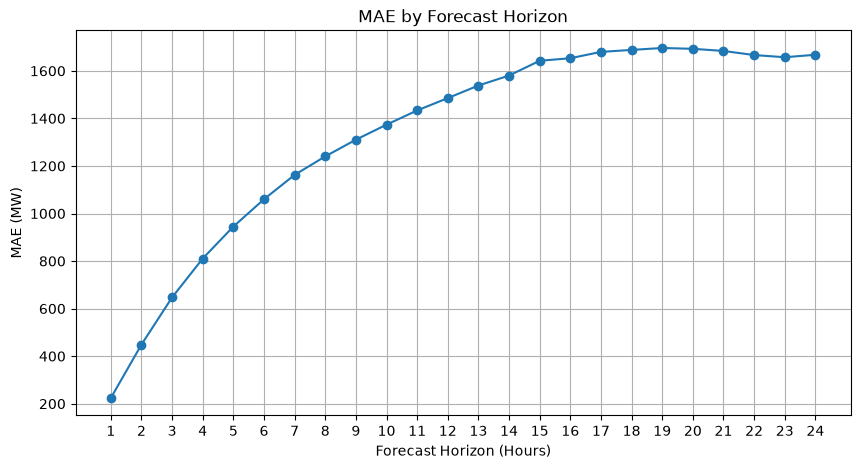

In [89]:
plt.figure(figsize=(10, 5))

plt.plot(
    results_24["Horizon"],
    results_24["MAE"],
    marker="o"
)

plt.title("MAE by Forecast Horizon")
plt.xlabel("Forecast Horizon (Hours)")
plt.ylabel("MAE (MW)")
plt.xticks(range(1, 25))
plt.grid(True)

plt.show()

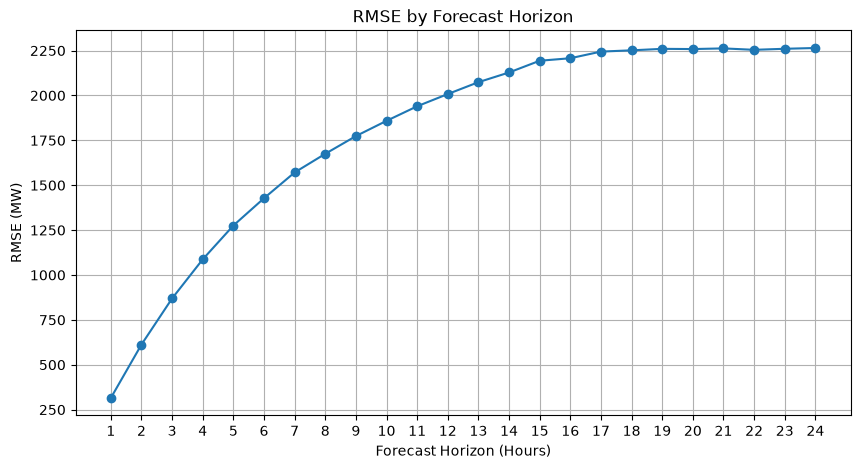

In [90]:
plt.figure(figsize=(10, 5))

plt.plot(
    results_24["Horizon"],
    results_24["RMSE"],
    marker="o"
)

plt.title("RMSE by Forecast Horizon")
plt.xlabel("Forecast Horizon (Hours)")
plt.ylabel("RMSE (MW)")
plt.xticks(range(1, 25))
plt.grid(True)

plt.show()

## 9. Error analysis

Where and when does the model fail? Error by horizon, largest errors, hour of day,
high- vs low-demand periods, and peak-demand underprediction.

In [91]:
error_analysis_24 = []

for h in range(1, 25):
    y_true = Y_val_24[f"target_{h}"].values
    y_pred = predictions_24[h]

    absolute_error = np.abs(y_true - y_pred)

    error_analysis_24.append({
        "Horizon": h,
        "MAE": np.mean(absolute_error),
        "Max_Error": np.max(absolute_error),
        "P95_Error": np.percentile(absolute_error, 95)
    })

error_analysis_24 = pd.DataFrame(error_analysis_24)

error_analysis_24

,Horizon,MAE,Max_Error,P95_Error
0,1,224.007155,3408.094793,633.514947
1,2,448.701095,5386.694532,1228.244498
2,3,647.244833,6362.637513,1756.361309
3,4,810.633442,6695.237236,2194.084431
4,5,945.015258,8065.042036,2601.015005
5,6,1060.067639,8303.863629,2931.511524
6,7,1162.550060,9950.984639,3218.150888
7,8,1240.237625,11691.021903,3418.049708
8,9,1310.411102,11443.069728,3625.470540
9,10,1373.705886,12699.883861,3803.077360


In [92]:
h = 24

error_df = pd.DataFrame({
    "Datetime": val_lgb["Datetime"].values,
    "Actual": Y_val_24[f"target_{h}"].values,
    "Predicted": predictions_24[h]
})

error_df["Absolute_Error"] = np.abs(
    error_df["Actual"] - error_df["Predicted"]
)

error_df = error_df.sort_values(
    "Absolute_Error",
    ascending=False
)

error_df.head(20)

,Datetime,Actual,Predicted,Absolute_Error
7554,2014-07-03 16:00:00,31493.0,46031.280627,14538.280627
7556,2014-07-03 18:00:00,31431.0,45614.426327,14183.426327
7555,2014-07-03 17:00:00,31469.0,45342.702447,13873.702447
7553,2014-07-03 15:00:00,31655.0,45375.014766,13720.014766
7552,2014-07-03 14:00:00,31920.0,45430.279432,13510.279432
3273,2014-01-06 06:00:00,42663.0,29503.708988,13159.291012
430,2013-09-09 18:00:00,48931.0,35999.994469,12931.005531
15236,2015-05-19 19:00:00,30066.0,42962.250908,12896.250908
3275,2014-01-06 08:00:00,47626.0,34826.974428,12799.025572
429,2013-09-09 17:00:00,48469.0,35805.185561,12663.814439


In [93]:
error_df["Hour"] = pd.to_datetime(error_df["Datetime"]).dt.hour

hourly_error = (
    error_df
    .groupby("Hour")["Absolute_Error"]
    .mean()
    .reset_index()
)

hourly_error

,Hour,Absolute_Error
0,0,1478.812269
1,1,1426.686835
2,2,1414.550767
3,3,1438.939504
4,4,1460.634058
5,5,1454.147527
6,6,1529.802530
7,7,1668.544324
8,8,1706.563624
9,9,1594.443231


In [94]:
hourly_demand = (
    val_lgb
    .groupby(val_lgb["Datetime"].dt.hour)["PJME_MW"]
    .mean()
    .reset_index()
)

hourly_demand.columns = ["Hour", "Average_Demand"]

hourly_demand

,Hour,Average_Demand
0,0,29041.752772
1,1,27211.451220
2,2,26128.511654
3,3,25521.601111
4,4,25323.630820
5,5,25723.016630
6,6,27171.287140
7,7,29572.293792
8,8,31234.847007
9,9,32118.334812


In [95]:
demand_threshold = val_lgb["PJME_MW"].median()

error_df["Demand_Level"] = np.where(
    error_df["Actual"] >= demand_threshold,
    "High Demand",
    "Low Demand"
)

demand_error = (
    error_df
    .groupby("Demand_Level")["Absolute_Error"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

demand_error.columns = [
    "Demand_Level",
    "Mean_Absolute_Error",
    "Median_Absolute_Error",
    "Count"
]

demand_error

,Demand_Level,Mean_Absolute_Error,Median_Absolute_Error,Count
0,High Demand,2012.562592,1551.390898,10831
1,Low Demand,1322.185063,1033.416974,10816


In [96]:
peak_threshold = error_df["Actual"].quantile(0.90)

peak_errors = error_df[
    error_df["Actual"] >= peak_threshold
].copy()

peak_errors["Error"] = (
    peak_errors["Actual"] - peak_errors["Predicted"]
)

peak_errors["Underprediction"] = (
    peak_errors["Predicted"] < peak_errors["Actual"]
)

peak_errors[[
    "Datetime",
    "Actual",
    "Predicted",
    "Error",
    "Underprediction"
]].head(20)

,Datetime,Actual,Predicted,Error,Underprediction
3273,2014-01-06 06:00:00,42663.0,29503.708988,13159.291012,True
430,2013-09-09 18:00:00,48931.0,35999.994469,12931.005531,True
3275,2014-01-06 08:00:00,47626.0,34826.974428,12799.025572,True
429,2013-09-09 17:00:00,48469.0,35805.185561,12663.814439,True
3272,2014-01-06 05:00:00,40259.0,27708.021576,12550.978424,True
3274,2014-01-06 07:00:00,45833.0,33399.186660,12433.813340,True
3276,2014-01-06 09:00:00,47365.0,34936.892274,12428.107726,True
431,2013-09-09 19:00:00,47673.0,35499.163042,12173.836958,True
3277,2014-01-06 10:00:00,47036.0,35048.061842,11987.938158,True
428,2013-09-09 16:00:00,47125.0,35378.073123,11746.926877,True


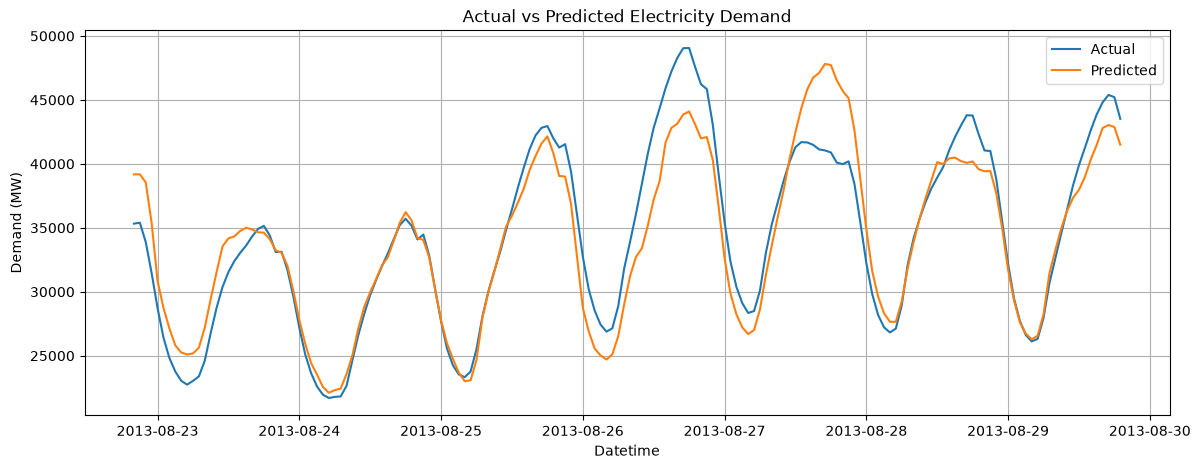

In [97]:
sample = error_df.sort_values("Datetime").iloc[:168].copy()

plt.figure(figsize=(14, 5))

plt.plot(
    sample["Datetime"],
    sample["Actual"],
    label="Actual"
)

plt.plot(
    sample["Datetime"],
    sample["Predicted"],
    label="Predicted"
)

plt.title("Actual vs Predicted Electricity Demand")
plt.xlabel("Datetime")
plt.ylabel("Demand (MW)")
plt.legend()
plt.grid(True)

plt.show()

## 10. XGBoost benchmark

Same features, targets, and split as LightGBM, for a like-for-like comparison.

In [98]:
xgb_model_h1 = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

In [99]:
xgb_model_h1.fit(
    X_train,
    Y_train_24["target_1"],
    eval_set=[(X_val, Y_val_24["target_1"])],
    verbose=False
)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [100]:
xgb_pred_h1 = xgb_model_h1.predict(X_val)

print("Prediction shape:", xgb_pred_h1.shape)

Prediction shape: (21647,)


In [101]:
xgb_mae_h1 = mean_absolute_error(
    Y_val_24["target_1"],
    xgb_pred_h1
)

xgb_rmse_h1 = np.sqrt(
    mean_squared_error(
        Y_val_24["target_1"],
        xgb_pred_h1
    )
)

print(f"XGBoost Horizon 1 MAE: {xgb_mae_h1:.2f}")
print(f"XGBoost Horizon 1 RMSE: {xgb_rmse_h1:.2f}")

XGBoost Horizon 1 MAE: 233.41
XGBoost Horizon 1 RMSE: 329.62


In [102]:
xgb_models_24 = {}

for h in range(1, 25):

    target = f"target_{h}"

    model = XGBRegressor(
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=8,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42
    )

    model.fit(
        X_train,
        Y_train_24[target],
        eval_set=[(X_val, Y_val_24[target])],
        verbose=False
    )

    xgb_models_24[h] = model

print("Number of XGBoost models:", len(xgb_models_24))

Number of XGBoost models: 24


In [103]:
xgb_predictions_24 = {}

for h in range(1, 25):
    xgb_predictions_24[h] = xgb_models_24[h].predict(X_val)

print("Number of prediction sets:", len(xgb_predictions_24))
print("Horizon 1 shape:", xgb_predictions_24[1].shape)
print("Horizon 24 shape:", xgb_predictions_24[24].shape)

Number of prediction sets: 24
Horizon 1 shape: (21647,)
Horizon 24 shape: (21647,)


In [104]:
xgb_results_24 = []

for h in range(1, 25):

    y_true = Y_val_24[f"target_{h}"].values
    y_pred = xgb_predictions_24[h]

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    xgb_results_24.append({
        "Horizon": h,
        "MAE": mae,
        "RMSE": rmse
    })

xgb_results_24 = pd.DataFrame(xgb_results_24)

xgb_results_24

,Horizon,MAE,RMSE
0,1,233.413816,329.618650
1,2,447.524297,618.280070
2,3,639.513502,868.378596
3,4,804.557350,1084.639442
4,5,934.773642,1262.450896
5,6,1052.647655,1421.576614
6,7,1158.167862,1564.420481
7,8,1241.473068,1681.315441
8,9,1309.187517,1777.248987
9,10,1387.295107,1880.469242


In [105]:
model_comparison = results_24[["Horizon", "MAE", "RMSE"]].merge(
    xgb_results_24,
    on="Horizon",
    suffixes=("_LightGBM", "_XGBoost")
)

model_comparison

,Horizon,MAE_LightGBM,RMSE_LightGBM,MAE_XGBoost,RMSE_XGBoost
0,1,224.007155,314.876041,233.413816,329.618650
1,2,448.701095,612.545269,447.524297,618.280070
2,3,647.244833,869.501308,639.513502,868.378596
3,4,810.633442,1087.146456,804.557350,1084.639442
4,5,945.015258,1275.454422,934.773642,1262.450896
5,6,1060.067639,1427.516054,1052.647655,1421.576614
6,7,1162.550060,1571.076723,1158.167862,1564.420481
7,8,1240.237625,1675.020703,1241.473068,1681.315441
8,9,1310.411102,1773.618330,1309.187517,1777.248987
9,10,1373.705886,1858.589444,1387.295107,1880.469242


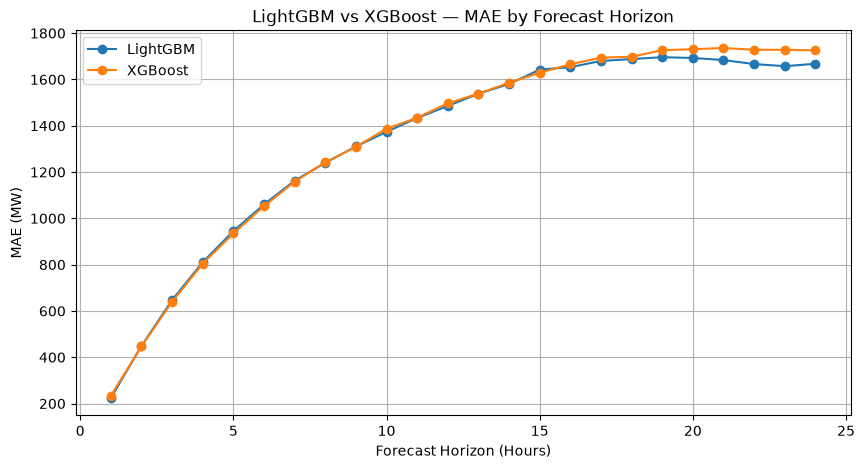

In [106]:
plt.figure(figsize=(10, 5))

plt.plot(
    model_comparison["Horizon"],
    model_comparison["MAE_LightGBM"],
    marker="o",
    label="LightGBM"
)

plt.plot(
    model_comparison["Horizon"],
    model_comparison["MAE_XGBoost"],
    marker="o",
    label="XGBoost"
)

plt.xlabel("Forecast Horizon (Hours)")
plt.ylabel("MAE (MW)")
plt.title("LightGBM vs XGBoost — MAE by Forecast Horizon")
plt.legend()
plt.grid(True)
plt.show()

## 11. From exploration to a reproducible pipeline

The comparison above favoured LightGBM at most horizons, which `src/train.py` confirms with a
cleaner protocol (early stopping on a separate slice of the training data, so the validation
partition is used only for model selection).

Experiment tracking, model registration, the final test-set evaluation, and the deployable
model export are performed by:

```bash
python -m src.train
```

See the project README for the reported results.